In [86]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, HistGradientBoostingRegressor)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

In [87]:
df = pd.read_csv(r"D:\tasks\Ames Housing Dataset(Target column SalePrice).csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [88]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [89]:
print(df.duplicated().sum())
df = df.drop(columns="Id")
print( df.shape)

0
(1460, 80)


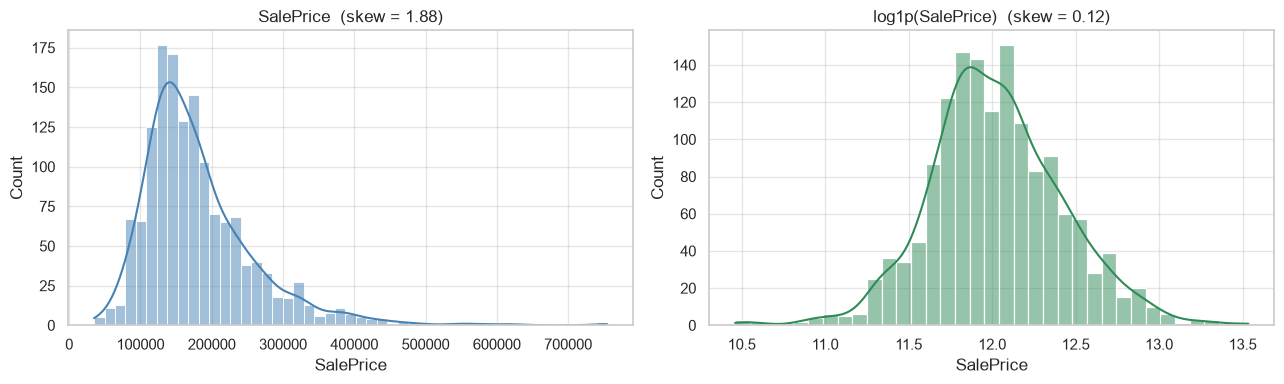

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title(f"SalePrice  (skew = {df['SalePrice'].skew():.2f})")

sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"log1p(SalePrice)  (skew = {np.log1p(df['SalePrice']).skew():.2f})")

plt.tight_layout()
plt.show()

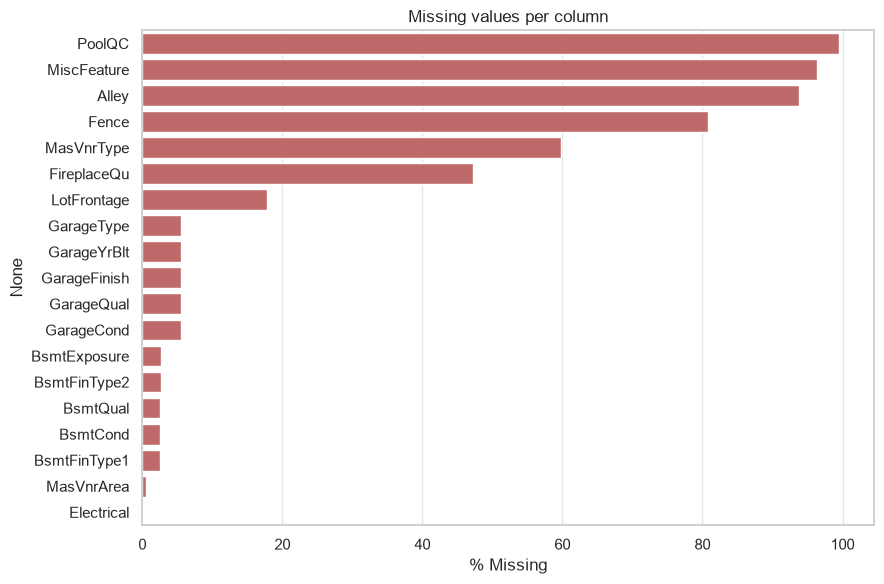

,missing %,count
PoolQC,99.52,1453
MiscFeature,96.30,1406
Alley,93.77,1369
Fence,80.75,1179
MasVnrType,59.73,872
FireplaceQu,47.26,690
LotFrontage,17.74,259
GarageType,5.55,81
GarageYrBlt,5.55,81
GarageFinish,5.55,81


In [91]:
miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_pct = (miss / len(df) * 100).round(2)

plt.figure(figsize=(9, 6))
sns.barplot(x=miss_pct.values, y=miss_pct.index, color="indianred")
plt.xlabel("% Missing")
plt.title("Missing values per column")
plt.tight_layout()
plt.show()

miss_pct.to_frame("missing %").assign(count=miss)

In [92]:
none_cols = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "PoolQC", "Fence", "MiscFeature", "MasVnrType"]
df[none_cols] = df[none_cols].fillna("None")

df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

df["HasGarage"] = (df["GarageType"] != "None").astype(int)
df = df.drop(columns="GarageYrBlt")

df["MSSubClass"] = df["MSSubClass"].astype(str)

left = df.isnull().sum()
left[left > 0]

LotFrontage    259
Electrical       1
dtype: int64

In [93]:
quality_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
quality_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

for c in quality_cols:
    df[c] = df[c].map(quality_map)

print(df[quality_cols].isnull().sum().sum())
df[quality_cols].head()

0


,ExterQual,ExterCond,BsmtQual,BsmtCond,HeatingQC,KitchenQual,FireplaceQu,GarageQual,GarageCond,PoolQC
0,4,3,4,3,5,4,0,3,3,0
1,3,3,4,3,5,3,3,3,3,0
2,4,3,4,3,5,4,3,3,3,0
3,3,3,3,4,4,4,4,3,3,0
4,4,3,4,3,5,4,3,3,3,0


In [94]:
df["TotalSF"]    = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["TotalBath"]  = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
df["HouseAge"]   = df["YrSold"] - df["YearBuilt"]
df["RemodAge"]   = df["YrSold"] - df["YearRemodAdd"]
df["HasPool"]    = (df["PoolArea"] > 0).astype(int)

print(df.shape)

(1460, 85)


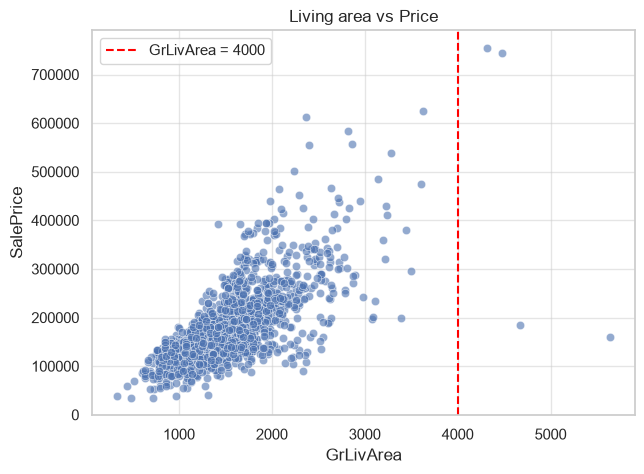

In [95]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.6)
plt.axvline(4000, color="red", ls="--", label="GrLivArea = 4000")
plt.legend()
plt.title("Living area vs Price")
plt.show()

In [96]:
outliers = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
print(len(outliers))
df = df.drop(index=outliers.index).reset_index(drop=True)
print(df.shape)

2
(1458, 85)


In [97]:
X = df.drop(columns="SalePrice")
y = np.log1p(df["SalePrice"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

y_test_real = np.expm1(y_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1166, 84) | Test: (292, 84)


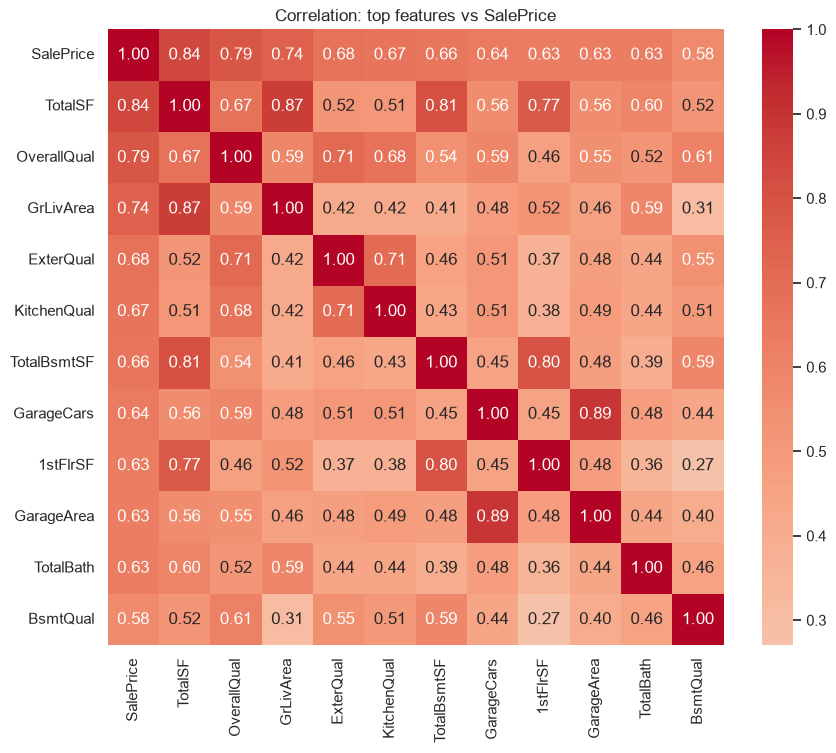

In [98]:
train_df = X_train.copy()
train_df["SalePrice"] = np.expm1(y_train)

corr_all = train_df.select_dtypes("number").corr()["SalePrice"].abs().sort_values(ascending=False)
top = corr_all.head(12).index

plt.figure(figsize=(10, 8))
sns.heatmap(train_df[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation: top features vs SalePrice")
plt.show()

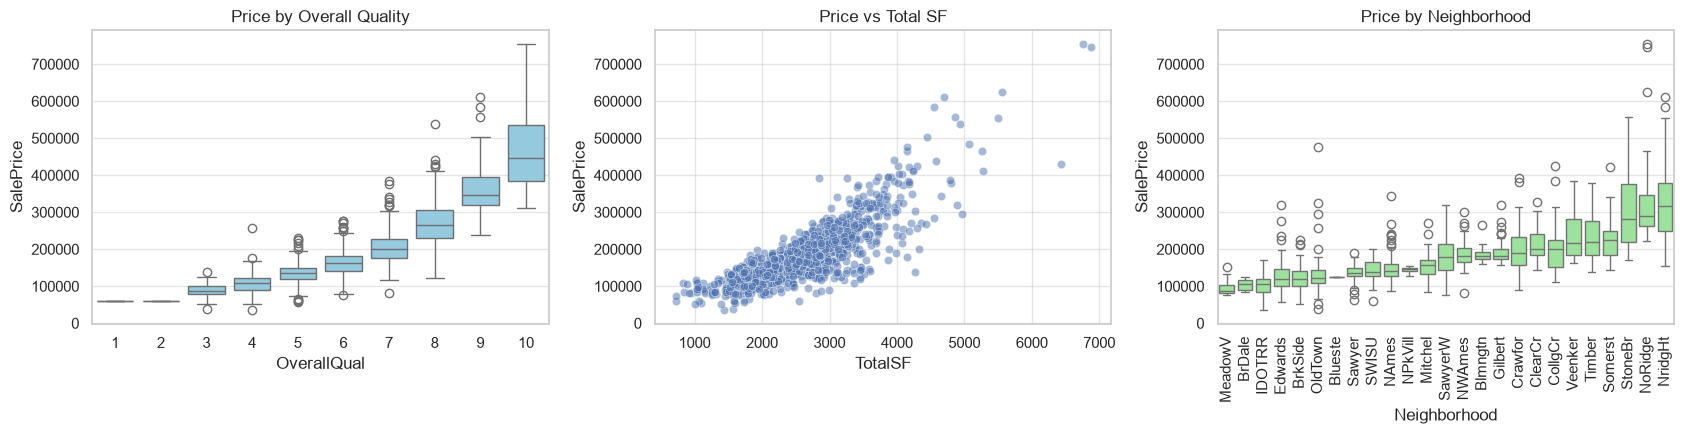

In [99]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(data=train_df, x="OverallQual", y="SalePrice", ax=axes[0], color="skyblue")
axes[0].set_title("Price by Overall Quality")

sns.scatterplot(data=train_df, x="TotalSF", y="SalePrice", alpha=0.5, ax=axes[1])
axes[1].set_title("Price vs Total SF")

order = train_df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
sns.boxplot(data=train_df, x="Neighborhood", y="SalePrice", order=order, ax=axes[2], color="lightgreen")
axes[2].tick_params(axis="x", rotation=90)
axes[2].set_title("Price by Neighborhood")

plt.tight_layout()
plt.show()

In [100]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print(f"{len(num_cols)}, {len(cat_cols)}")

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

Xt = preprocessor.fit_transform(X_train)
print(Xt.shape)
print(np.isnan(Xt).sum())

50, 34
(1166, 277)
0


In [101]:
models = {
    "Linear Regression":    LinearRegression(),
    "Ridge":                Ridge(alpha=10),
    "Lasso":                Lasso(alpha=0.001, max_iter=20000),
    "ElasticNet":           ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000),
    "KNN":                  KNeighborsRegressor(n_neighbors=7, weights="distance"),
    "SVR":                  SVR(C=10, epsilon=0.05),
    "Decision Tree":        DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest":        RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees":          ExtraTreesRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "AdaBoost":             AdaBoostRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting":    GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                                                      subsample=0.8, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
if XGBRegressor is not None:
    models["XGBoost"] = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=3, subsample=0.8,
                                     colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
if LGBMRegressor is not None:
    models["LightGBM"] = LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=15, subsample=0.8,
                                       colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted, preds = [], {}, {}

for name, model in models.items():
    t0 = time.time()
    pipe = Pipeline([("prep", preprocessor), ("model", model)])

    cv_rmse = np.sqrt(-cross_val_score(pipe, X_train, y_train, cv=kf,
                                       scoring="neg_mean_squared_error", n_jobs=1)).mean()

    pipe.fit(X_train, y_train)
    pred = np.expm1(pipe.predict(X_test))

    fitted[name], preds[name] = pipe, pred
    rows.append({
        "Model": name,
        "CV RMSE (log)": cv_rmse,
        "Test RMSE": np.sqrt(mean_squared_error(y_test_real, pred)),
        "Test MAE":  mean_absolute_error(y_test_real, pred),
        "Test R2":   r2_score(y_test_real, pred),
        "Time (s)":  time.time() - t0,
    })
    print(f"✔ {name:<22} R2 = {rows[-1]['Test R2']:.4f}   ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Test RMSE").reset_index(drop=True)
results.round(4)

✔ Linear Regression      R2 = 0.9094   (3.4s)
✔ Ridge                  R2 = 0.9260   (2.2s)
✔ Lasso                  R2 = 0.9323   (2.1s)
✔ ElasticNet             R2 = 0.9301   (2.3s)
✔ KNN                    R2 = 0.8289   (1.0s)
✔ SVR                    R2 = 0.9089   (2.4s)
✔ Decision Tree          R2 = 0.7100   (1.1s)
✔ Random Forest          R2 = 0.9021   (16.3s)
✔ Extra Trees            R2 = 0.9119   (17.7s)
✔ AdaBoost               R2 = 0.8454   (28.1s)
✔ Gradient Boosting      R2 = 0.9375   (39.4s)
✔ HistGradientBoosting   R2 = 0.9085   (24.5s)
✔ XGBoost                R2 = 0.9376   (10.2s)
✔ LightGBM               R2 = 0.9252   (5.8s)


,Model,CV RMSE (log),Test RMSE,Test MAE,Test R2,Time (s)
0,XGBoost,0.1156,18559.4350,13605.1649,0.9376,10.1884
1,Gradient Boosting,0.1175,18583.0602,13478.3799,0.9375,39.3971
2,Lasso,0.1134,19344.4139,13955.5430,0.9323,2.1100
3,ElasticNet,0.1122,19648.3344,14095.6711,0.9301,2.2542
4,Ridge,0.1123,20220.9840,14492.9130,0.9260,2.2339
5,LightGBM,0.1232,20332.3899,14299.1403,0.9252,5.7582
6,Extra Trees,0.1295,22063.1249,15801.2779,0.9119,17.7106
7,Linear Regression,0.1296,22375.9483,15672.1390,0.9094,3.3881
8,SVR,0.1471,22435.1177,15640.0596,0.9089,2.4500
9,HistGradientBoosting,0.1266,22482.2459,15065.3541,0.9085,24.4856


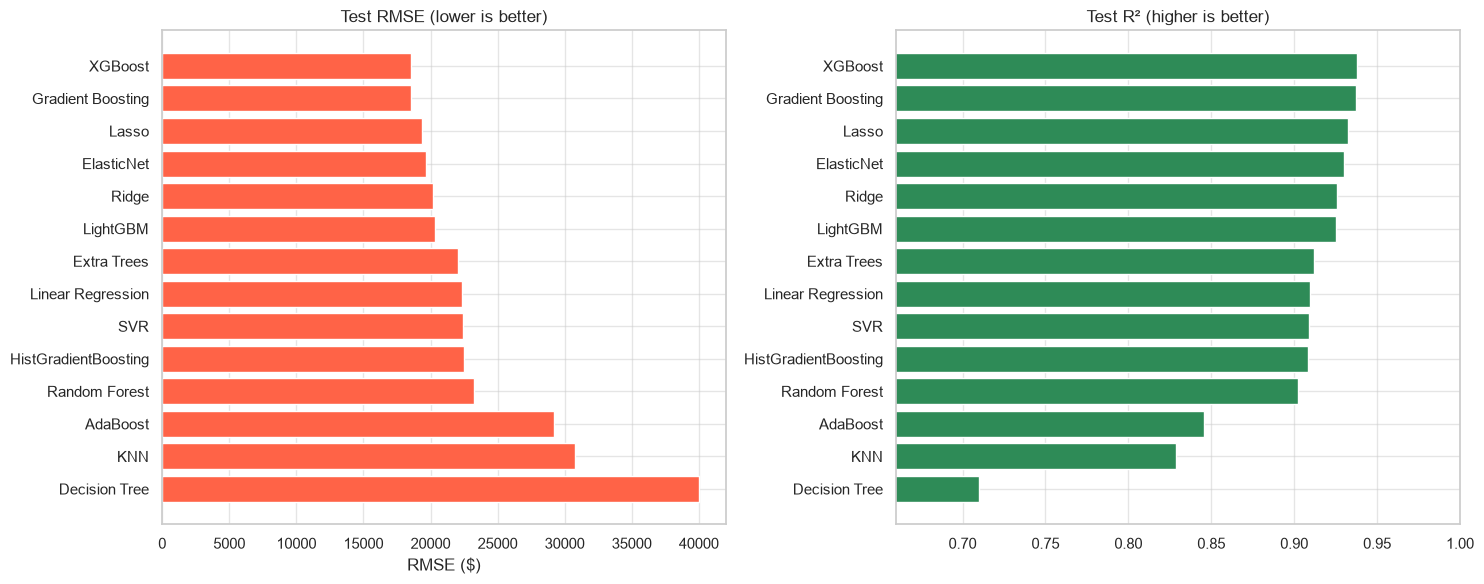

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

order = results.sort_values("Test RMSE", ascending=False)
axes[0].barh(order["Model"], order["Test RMSE"], color="tomato")
axes[0].set_title("Test RMSE (lower is better)")
axes[0].set_xlabel("RMSE ($)")

order = results.sort_values("Test R2")
axes[1].barh(order["Model"], order["Test R2"], color="seagreen")
axes[1].set_xlim(max(0, order["Test R2"].min() - 0.05), 1)
axes[1].set_title("Test R² (higher is better)")

plt.tight_layout()
plt.show()

In [103]:
best_name = results.loc[0, "Model"]
best_pred = preds[best_name]
print("أفضل موديل:", best_name)
print(results.loc[0].drop("Model").astype(float).round(4).to_string())

أفضل موديل: XGBoost
CV RMSE (log)        0.1156
Test RMSE        18559.4350
Test MAE         13605.1649
Test R2              0.9376
Time (s)            10.1884


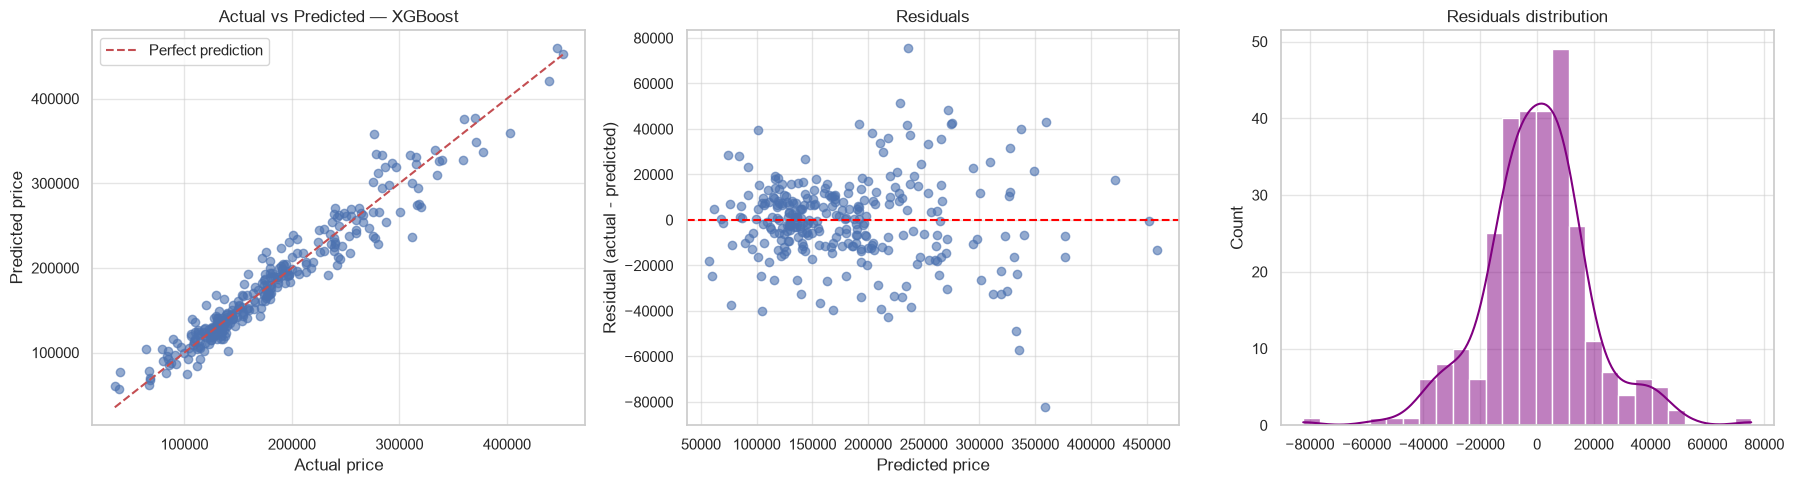

In [104]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_test_real, best_pred, alpha=0.6)
lims = [y_test_real.min(), y_test_real.max()]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title(f"Actual vs Predicted — {best_name}")
axes[0].legend()

resid = y_test_real.values - best_pred
axes[1].scatter(best_pred, resid, alpha=0.6)
axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("Predicted price"); axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals")

sns.histplot(resid, kde=True, ax=axes[2], color="purple")
axes[2].set_title("Residuals distribution")

plt.tight_layout()
plt.show()